# 05 · Cohort Retention and Lifetime Value

**Questions**

1. How quickly do new poker players drop off, and when does the base stabilize?
2. What is a new player worth over 3, 6, 12, 24 and 36 months?
3. Which early signals separate high-value players from the rest?
4. Roughly how much could we spend to acquire a player?

**Value measure:** net deposits, meaning money deposited minus money withdrawn (completed transactions only). "Lifetime value" (LTV) here means a player's total net deposits from their first poker month up to a given month. The data has no rake or fee field, so operator revenue cannot be measured directly. Net deposits are a simple, assumption-free proxy, but an upper bound: they include money lost to other players, money spent on other products in the same account, and balances not yet withdrawn. For scale, this cohort's net deposits were EUR 5.2M over the period, while its net loss at the poker tables was EUR 1.1M.

Reads `dim_player`, `fct_player_day`, `fct_player_week`. Writes `agg_player_month` and exports `outputs/cohort_retention.csv`, `outputs/ltv_curves.csv` and `outputs/player_segments.csv`.

In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
con = sqlite3.connect(ROOT / "data" / "poker.db")
NAVY, GREY, RED, GREEN = "#1f4e79", "#8c8c8c", "#b22222", "#2e7d32"
LAST_MONTH = "2020-06-01"

def q(sql):
    return pd.read_sql_query(sql, con)

def run(sql):
    con.executescript(sql); con.commit()

## 1. Player-month table

Each player's months are counted from their first month of poker play (month 0).

One important caveat: the deposit and withdrawal records belong to the player's **account**, which can also be used for other products such as sports betting. Net deposits therefore measure the value of the account, not of poker alone. To keep cohorts comparable, money moved **before** a player's first poker month gets a negative month number and is left out of the lifetime value curves.

In [2]:
run(f"""
drop table if exists agg_player_month;
create table agg_player_month as
with m as (
    select f.player_id, f.month_start,
           max(f.poker_active) as poker_active,
           sum(f.net_deposits) as net_deposits,
           sum(f.deposit_amount) as deposits
    from fct_player_day f group by 1, 2
)
select m.player_id, d.first_play_month, m.month_start,
       (cast(substr(m.month_start, 1, 4) as integer) - cast(substr(d.first_play_month, 1, 4) as integer)) * 12
            + cast(substr(m.month_start, 6, 2) as integer) - cast(substr(d.first_play_month, 6, 2) as integer) as month_num,
       m.poker_active, m.net_deposits, m.deposits
from m join dim_player d on d.player_id = m.player_id
where d.first_play_month is not null;
""")
pm = q("select * from agg_player_month")
players = q("select * from dim_player where first_play_month is not null")
players["months_observed"] = ((pd.Timestamp(LAST_MONTH).year - pd.to_datetime(players.first_play_month).dt.year) * 12
                              + pd.Timestamp(LAST_MONTH).month - pd.to_datetime(players.first_play_month).dt.month + 1)
print(f"{len(players):,} players, {len(pm):,} player-months")

5,025 players, 41,644 player-months


## 2. Cohorts

A **cohort** is simply a group of players who started at the same time, so they can be compared fairly. Everyone here opened an account in February 2015, but first poker play is spread out, so players are grouped by the month they first played poker. February 2015 holds 64% of players, so later months are grouped to keep cohorts large enough to read.

In [3]:
def cohort_group(month):
    if month == "2015-02-01": return "1. Feb 2015"
    if month == "2015-03-01": return "2. Mar 2015"
    if month <= "2015-12-01": return "3. Apr-Dec 2015"
    return "4. 2016 or later"

players["cohort"] = players.first_play_month.map(cohort_group)
pm = pm.merge(players[["player_id", "cohort", "months_observed"]], on="player_id")
players.groupby("cohort").agg(players=("player_id", "count"),
                              median_months_observed=("months_observed", "median"))

,players,median_months_observed
cohort,,
1. Feb 2015,3215,65.0
2. Mar 2015,558,64.0
3. Apr-Dec 2015,626,61.0
4. 2016 or later,626,40.0


## 3. Retention: share of each cohort playing poker in month N

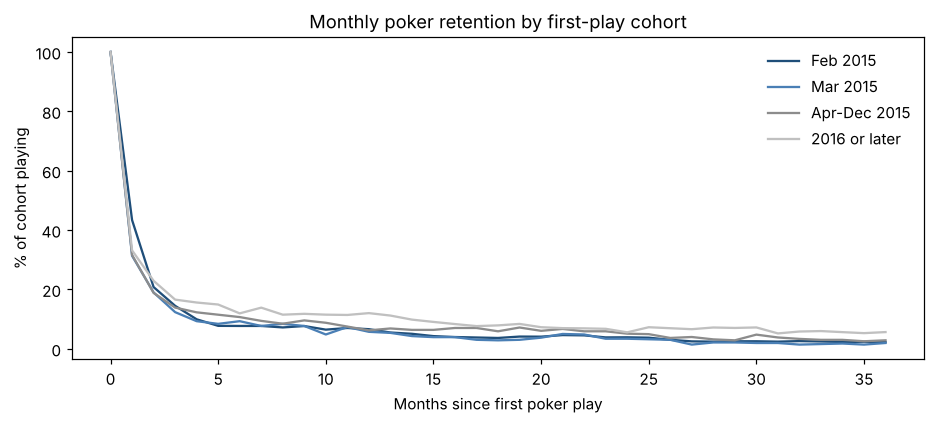

,1. Feb 2015,2. Mar 2015,3. Apr-Dec 2015,4. 2016 or later
1,43.4,31.4,31.6,33.2
3,14.5,12.4,13.9,16.6
6,7.7,9.3,10.7,12.0
12,6.6,5.7,6.2,12.0
24,3.9,3.4,5.1,5.6
36,2.3,2.0,2.9,5.6


In [4]:
def retention(df, group_col, max_month=36):
    size = players.groupby(group_col).player_id.nunique()
    out = {}
    for g, n in size.items():
        eligible = players[(players[group_col] == g)]
        row = {}
        for k in range(max_month + 1):
            base = eligible[eligible.months_observed > k]
            if len(base) < 30:            # too few players with k months of history
                break
            active = df[(df.month_num == k) & (df.poker_active == 1) & (df.player_id.isin(base.player_id))].player_id.nunique()
            row[k] = active / len(base)
        out[g] = row
    return pd.DataFrame(out)

ret = retention(pm, "cohort")
fig, ax = plt.subplots(figsize=(10, 3.8))
for col, color in zip(ret.columns, [NAVY, "#4a7fb5", GREY, "#c0c0c0"]):
    ax.plot(ret.index, ret[col] * 100, label=col[3:], color=color)
ax.set_title("Monthly poker retention by first-play cohort")
ax.set_xlabel("Months since first poker play"); ax.set_ylabel("% of cohort playing")
ax.legend(frameon=False)
(ret.rename_axis("month_num").reset_index()
    .melt(id_vars="month_num", var_name="cohort", value_name="retention")
    .dropna().to_csv(ROOT / "outputs" / "cohort_retention.csv", index=False))   # long format for BI tools
(ret.loc[[1, 3, 6, 12, 24, 36]] * 100).round(1)

- **Fewer than half of new players come back in their second month** (43% of the February 2015 starters, about a third for later groups), and only about 6-7% of the 2015 cohorts are still playing at month 12.
- **After month 12 the curves flatten.** Players who make it through the first year tend to stay for years.
- Players who tried poker later, after starting on another product, stay somewhat longer than the February 2015 starters. They were already engaged account holders when they arrived, so cross-sell players are not lower quality.

## 4. Lifetime value curves

Average cumulative net deposits per player, counting only players with enough history for each horizon.

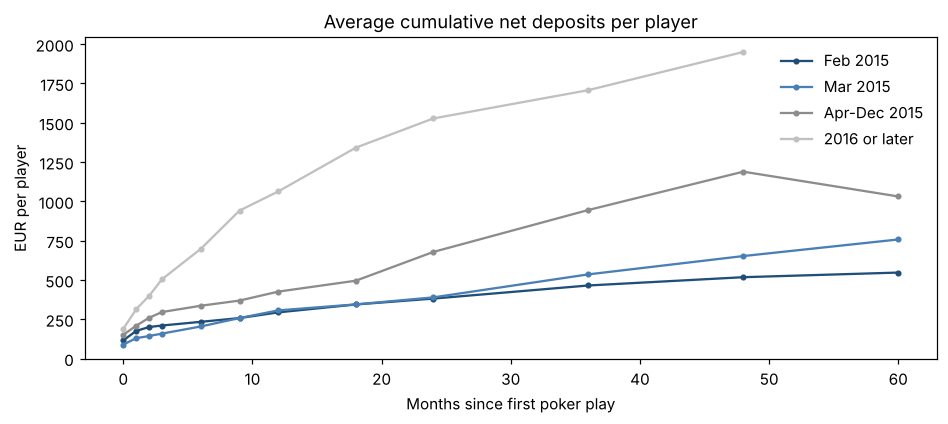

cohort,1. Feb 2015,2. Mar 2015,3. Apr-Dec 2015,4. 2016 or later
month,,,,
3,210.0,159.0,296.0,504.0
6,233.0,204.0,336.0,697.0
12,294.0,306.0,426.0,1063.0
24,381.0,389.0,678.0,1527.0
36,465.0,535.0,945.0,1707.0


In [5]:
def ltv_curve(group_col, horizons=(0, 1, 2, 3, 6, 9, 12, 18, 24, 36, 48, 60)):
    rows = []
    for g, grp in players.groupby(group_col):
        for h in horizons:
            elig = grp[grp.months_observed > h]
            if len(elig) < 30:
                continue
            val = pm[(pm.player_id.isin(elig.player_id)) & (pm.month_num.between(0, h))].groupby("player_id").net_deposits.sum()
            val = val.reindex(elig.player_id, fill_value=0)
            rows.append({group_col: g, "month": h, "players": len(elig),
                         "mean_ltv": val.mean(), "median_ltv": val.median()})
    return pd.DataFrame(rows)

ltv = ltv_curve("cohort")
fig, ax = plt.subplots(figsize=(10, 3.8))
for (g, d), color in zip(ltv.groupby("cohort"), [NAVY, "#4a7fb5", GREY, "#c0c0c0"]):
    ax.plot(d.month, d.mean_ltv, marker="o", markersize=3, label=g[3:], color=color)
ax.set_title("Average cumulative net deposits per player")
ax.set_xlabel("Months since first poker play"); ax.set_ylabel("EUR per player")
ax.legend(frameon=False)
ltv.to_csv(ROOT / "outputs" / "ltv_curves.csv", index=False)
ltv.pivot(index="month", columns="cohort", values="mean_ltv").loc[[3, 6, 12, 24, 36]].round(0)

In [6]:
ltv.pivot(index="month", columns="cohort", values="median_ltv").loc[[3, 6, 12, 24, 36]].round(0)

cohort,1. Feb 2015,2. Mar 2015,3. Apr-Dec 2015,4. 2016 or later
month,,,,
3,50.0,36.0,54.0,60.0
6,50.0,41.0,75.0,75.0
12,51.0,50.0,94.0,100.0
24,55.0,51.0,112.0,124.0
36,60.0,56.0,120.0,125.0


**The mean and the median tell very different stories.** The average February 2015 starter is worth about EUR 290 after 12 months, but the median player is worth about EUR 50. Value is concentrated in a small group of players.

Each point uses only players with enough history, so the last points of a curve rest on fewer players; the dip at month 60 for Apr-Dec 2015 reflects that smaller group, not value going down.

Later cohorts show higher values. Part of that is real (they arrived as engaged customers), and part comes from the account-level caveat above: their deposits also fund other products they were already using.

Median lifetime net deposits EUR 90; mean EUR 1,041; 7% of players withdrew more than they deposited.


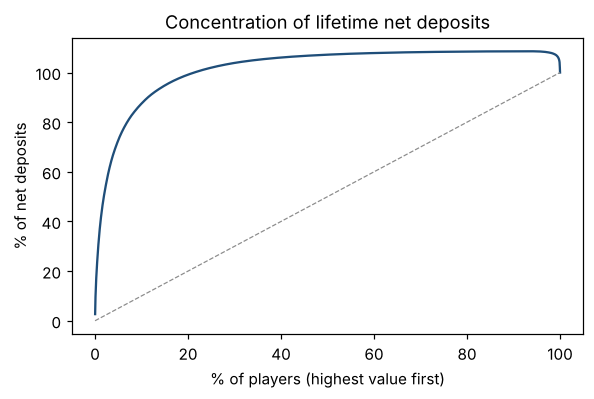

,top_share_of_players,share_of_net_deposits
0,1%,37%
1,5%,73%
2,10%,87%
3,20%,99%


In [7]:
v = players.lifetime_net_deposits.sort_values(ascending=False).reset_index(drop=True)
share = v.cumsum() / v.sum()
conc = pd.DataFrame({
    "top_share_of_players": ["1%", "5%", "10%", "20%"],
    "share_of_net_deposits": [f"{share.iloc[int(len(v) * p) - 1]:.0%}" for p in [0.01, 0.05, 0.10, 0.20]],
})
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(v) + 1) / len(v) * 100, share * 100, color=NAVY)
ax.plot([0, 100], [0, 100], color=GREY, linestyle="--", linewidth=0.8)
ax.set_title("Concentration of lifetime net deposits")
ax.set_xlabel("% of players (highest value first)"); ax.set_ylabel("% of net deposits")
print(f"Median lifetime net deposits EUR {v.median():,.0f}; mean EUR {v.mean():,.0f}; {(v < 0).mean():.0%} of players withdrew more than they deposited.")
conc

**The top 10% of players bring in close to 90% of net deposits.** For this business, finding and keeping high-value players early matters far more than average retention.

## 5. Early signals of value

Can we tell in the first four weeks who will become valuable? Players are grouped by how many of their first four weeks they played poker.

In [8]:
early = q("""
with first_week as (
    select player_id, min(week_start) as w0 from fct_player_week where poker_active = 1 group by 1
)
select f.player_id, sum(w.poker_active) as active_weeks_first_4
from first_week f
join fct_player_week w
  on w.player_id = f.player_id and w.week_start between f.w0 and date(f.w0, '+21 days')
group by 1
""")
seg = players.merge(early, on="player_id", how="left")
seg["active_weeks_first_4"] = seg.active_weeks_first_4.fillna(1).astype(int)
seg["first_4_weeks"] = seg.active_weeks_first_4.map({1: "1 of 4 weeks", 2: "2 of 4 weeks", 3: "3 of 4 weeks", 4: "All 4 weeks"})

def value_at(h, df):
    elig = df[df.months_observed > h]
    val = pm[(pm.player_id.isin(elig.player_id)) & (pm.month_num.between(0, h))].groupby("player_id").net_deposits.sum()
    return val.reindex(elig.player_id, fill_value=0)

def active_month_12(df):
    elig = df[df.months_observed > 12]
    act = pm[(pm.month_num == 12) & (pm.poker_active == 1)].player_id
    return elig.player_id.isin(act).mean()

def segment_table(col):
    rows = []
    for g, d in seg.groupby(col):
        ltv12 = value_at(12, d)
        rows.append({col: g, "players": len(d), "share_of_players": len(d) / len(seg),
                     "still_playing_month_12": active_month_12(d),
                     "mean_ltv_12m": ltv12.mean(), "median_ltv_12m": ltv12.median(),
                     "share_of_12m_value": ltv12.sum()})
    t = pd.DataFrame(rows)
    t["share_of_12m_value"] = t.share_of_12m_value / t.share_of_12m_value.sum()
    return t

eng = segment_table("first_4_weeks")
print(eng.round(3).to_string(index=False))
eng.style.format({"share_of_players": "{:.0%}", "still_playing_month_12": "{:.0%}", "mean_ltv_12m": "EUR {:,.0f}",
                  "median_ltv_12m": "EUR {:,.0f}", "share_of_12m_value": "{:.0%}"}).hide(axis="index")

first_4_weeks  players  share_of_players  still_playing_month_12  mean_ltv_12m  median_ltv_12m  share_of_12m_value
 1 of 4 weeks     2301             0.458                   0.028       292.269          36.056               0.337
 2 of 4 weeks     1214             0.242                   0.058       381.500          61.200               0.235
 3 of 4 weeks      722             0.144                   0.095       561.449          91.800               0.203
  All 4 weeks      788             0.157                   0.193       569.008         169.361               0.225


first_4_weeks,players,share_of_players,still_playing_month_12,mean_ltv_12m,median_ltv_12m,share_of_12m_value
1 of 4 weeks,2301,46%,3%,EUR 292,EUR 36,34%
2 of 4 weeks,1214,24%,6%,EUR 382,EUR 61,24%
3 of 4 weeks,722,14%,9%,EUR 561,EUR 92,20%
All 4 weeks,788,16%,19%,EUR 569,EUR 169,22%


**Engagement in the first month is a strong early signal for retention.** Players active in all of their first four weeks are seven times as likely to still be playing at month 12 as players who show up in only one week (19% vs 3%), and their median 12-month value is about five times higher (EUR 169 vs EUR 36).

The one-week group still contributes about a third of 12-month value, because some large depositors play intensively for a short time and leave. So early engagement predicts **who stays**, while deposit size predicts **who is valuable now**; the CRM team needs both signals.

Practical rule: **get a new player back for a second and third week**, and treat a large first deposit from a one-week player as a churn risk to act on quickly.

## 6. Value by market

In [9]:
mk = segment_table("market")
mk = mk[mk.players >= 100].sort_values("mean_ltv_12m", ascending=False)
print(mk.round(3).to_string(index=False))
mk.style.format({"share_of_players": "{:.0%}", "still_playing_month_12": "{:.0%}", "mean_ltv_12m": "EUR {:,.0f}",
                 "median_ltv_12m": "EUR {:,.0f}", "share_of_12m_value": "{:.0%}"}).hide(axis="index")

        market  players  share_of_players  still_playing_month_12  mean_ltv_12m  median_ltv_12m  share_of_12m_value
   Switzerland      185             0.037                   0.038       738.948         187.214               0.070
       Belgium      300             0.060                   0.110       715.098          80.000               0.103
       Austria      216             0.043                   0.075       594.971          75.750               0.065
 Rest of World      183             0.036                   0.061       554.545          73.708               0.051
   Netherlands      140             0.028                   0.081       513.704         146.000               0.035
       Germany     1415             0.282                   0.068       464.338          70.000               0.329
        France     1251             0.249                   0.073       354.567          60.000               0.226
         Spain      335             0.067                   0.047       

market,players,share_of_players,still_playing_month_12,mean_ltv_12m,median_ltv_12m,share_of_12m_value
Switzerland,185,4%,4%,EUR 739,EUR 187,7%
Belgium,300,6%,11%,EUR 715,EUR 80,10%
Austria,216,4%,7%,EUR 595,EUR 76,7%
Rest of World,183,4%,6%,EUR 555,EUR 74,5%
Netherlands,140,3%,8%,EUR 514,EUR 146,4%
Germany,1415,28%,7%,EUR 464,EUR 70,33%
France,1251,25%,7%,EUR 355,EUR 60,23%
Spain,335,7%,5%,EUR 237,EUR 35,4%
Czechia,190,4%,8%,EUR 211,EUR 32,2%
Other Europe,383,8%,7%,EUR 188,EUR 34,4%


Markets differ in both size and quality. Germany and France supply over half of players and of 12-month value. Belgium and Switzerland are smaller but worth far more per player, while the United Kingdom has average retention but low value per player. Markets with a high average but a low median, such as Belgium, depend on a few large players, which makes them riskier to forecast and worth watching in the weekly report. Markets with fewer than 100 players are left out because one player can move the average.

## 7. How much could we spend to acquire a player?

Break-even acquisition cost here is simply the average net deposits a new player brings in over the payback window. Because net deposits include money lost to other players and spent on other products, this is an **upper bound**: the real affordable cost is lower.

In [10]:
feb = players[players.cohort == "1. Feb 2015"]
cac = pd.DataFrame([{"payback_window_months": m, "break_even_cac_upper_bound_eur": round(value_at(m, feb).mean())}
                    for m in [6, 12, 24]])
cac

,payback_window_months,break_even_cac_upper_bound_eur
0,6,233
1,12,294
2,24,381


- **The payback window matters a lot.** Value keeps building for years among retained players, so a 24-month window supports a much higher acquisition cost than a 6-month one.
- **An average hides the concentration.** Most new players never pay back; the budget works because a small group does. Acquisition channels should be judged on how many engaged players they bring, not on sign-up volume.

## Takeaways

1. **The first month decides who stays.** Fewer than half of new players return in their second month, and players active every week of their first month are seven times as likely to still be playing a year later.
2. **Value is highly concentrated.** The top 10% of players bring in close to 90% of net deposits; VIP identification and retention deserve priority.
3. **Retained players are durable.** Retention flattens after a year and lifetime value keeps growing, which supports longer payback windows in acquisition budgets.

In [11]:
seg[["player_id", "cohort", "market", "age_band", "gender", "first_deposit_category", "first_4_weeks",
     "lifetime_net_deposits", "poker_days"]].to_csv(ROOT / "outputs" / "player_segments.csv", index=False)
con.close()